# Linear regression with real clinical data
## Diabetes progression and baseline BMI

This notebook uses the diabetes dataset distributed with scikit-learn.

Each patient has baseline measurements, and the response is a quantitative measure of disease progression one year later.

We use one predictor,

$$
X=\text{baseline BMI feature},
$$

and one response,

$$
Y=\text{disease progression measure}.
$$

The conceptual progression is

$$
\boxed{
\mathbb E[Y]
\rightarrow
\mathbb E[Y\mid X=x]
\rightarrow
\beta_0+\beta_1x.
}
$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_diabetes

plt.rcParams["figure.figsize"]=(7,4.8)
rng=np.random.default_rng(12)

data=load_diabetes(as_frame=True)
df=data.frame.copy()

x=df["bmi"].to_numpy()
y=df["target"].to_numpy()

print(f"n = {len(df)}")
df[["bmi","target"]].head()

n = 442


,bmi,target
0,0.061696,151.0
1,-0.051474,75.0
2,0.044451,141.0
3,-0.011595,206.0
4,-0.036385,135.0


## 1. Ignore BMI: one prediction for every patient

If we ignore all baseline information, then the best constant squared-error predictor is

$$
\hat Y=\bar Y.
$$

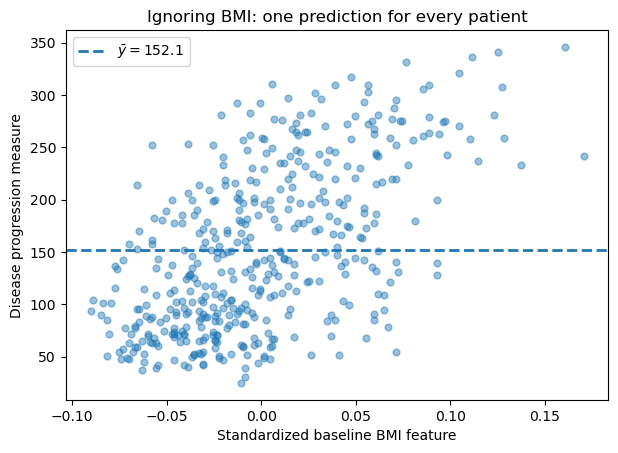

In [2]:
ybar=y.mean()

plt.scatter(x,y,alpha=0.45,s=24)
plt.axhline(ybar,linestyle="--",linewidth=2,label=rf"$\bar y={ybar:.1f}$")
plt.xlabel("Standardized baseline BMI feature")
plt.ylabel("Disease progression measure")
plt.title("Ignoring BMI: one prediction for every patient")
plt.legend()
plt.show()

### Question

Does baseline BMI appear to contain information about the response?

If yes, then predicting the same \(\bar Y\) for everyone throws information away.

## 2. The prediction target becomes conditional expectation

Once \(X\) is observed, the relevant population target is

$$
\boxed{
m(x)=\mathbb E[Y\mid X=x].
}
$$

Under squared-error loss, this is the optimal prediction of \(Y\) given \(X=x\).

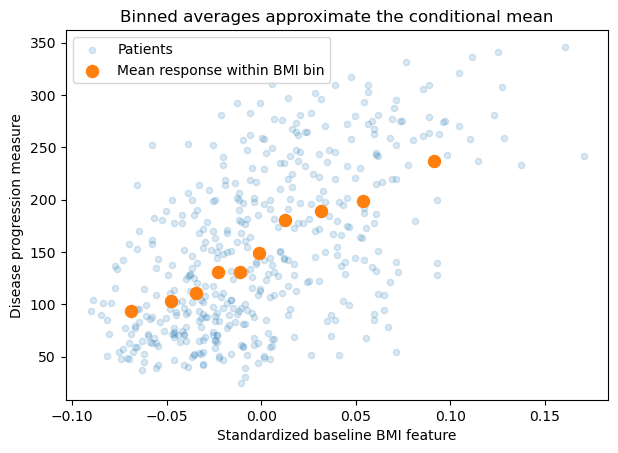

In [3]:
tmp=pd.DataFrame({"x":x,"y":y})
tmp["bin"]=pd.qcut(tmp["x"],q=10,duplicates="drop")

binned=(tmp.groupby("bin",observed=True)
          .agg(x_mean=("x","mean"),
               y_mean=("y","mean"),
               n=("y","size"))
          .reset_index())

plt.scatter(x,y,alpha=0.17,s=20,label="Patients")
plt.scatter(binned["x_mean"],binned["y_mean"],s=75,label="Mean response within BMI bin")
plt.xlabel("Standardized baseline BMI feature")
plt.ylabel("Disease progression measure")
plt.title("Binned averages approximate the conditional mean")
plt.legend()
plt.show()

## 3. Simplest structural model: a line

The conditional mean is unknown.

The simplest nonconstant model is

$$
\boxed{
\mathbb E[Y\mid X=x]
=
\beta_0+\beta_1x.
}
$$

Define

$$
\varepsilon
=
Y-\mathbb E[Y\mid X].
$$

Then

$$
\boxed{
Y=\beta_0+\beta_1X+\varepsilon,
\qquad
\mathbb E[\varepsilon\mid X]=0.
}
$$

beta0_hat = 152.133
beta1_hat = 949.435


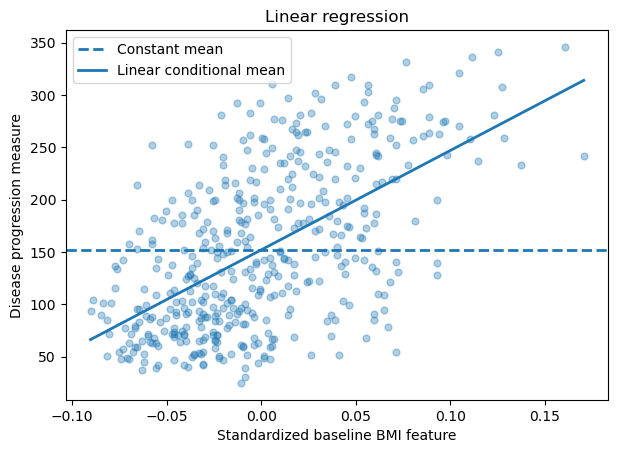

In [4]:
xbar=x.mean()
ybar=y.mean()

beta1=np.sum((x-xbar)*(y-ybar))/np.sum((x-xbar)**2)
beta0=ybar-beta1*xbar

xx=np.linspace(x.min(),x.max(),200)
yy=beta0+beta1*xx

print(f"beta0_hat = {beta0:.3f}")
print(f"beta1_hat = {beta1:.3f}")

plt.scatter(x,y,alpha=0.35,s=24)
plt.axhline(ybar,linestyle="--",linewidth=2,label="Constant mean")
plt.plot(xx,yy,linewidth=2,label="Linear conditional mean")
plt.xlabel("Standardized baseline BMI feature")
plt.ylabel("Disease progression measure")
plt.title("Linear regression")
plt.legend()
plt.show()

Because the BMI feature in this dataset is standardized, the numerical slope should not be interpreted as "per BMI unit" in ordinary clinical units.

The key statistical interpretation is

$$
\beta_1
=
\text{change in expected response as the predictor changes}.
$$

## 4. What remains after using \(X\)?

The fitted value is

$$
\hat y_i=\hat\beta_0+\hat\beta_1x_i.
$$

The residual is

$$
\boxed{
e_i=y_i-\hat y_i.
}
$$

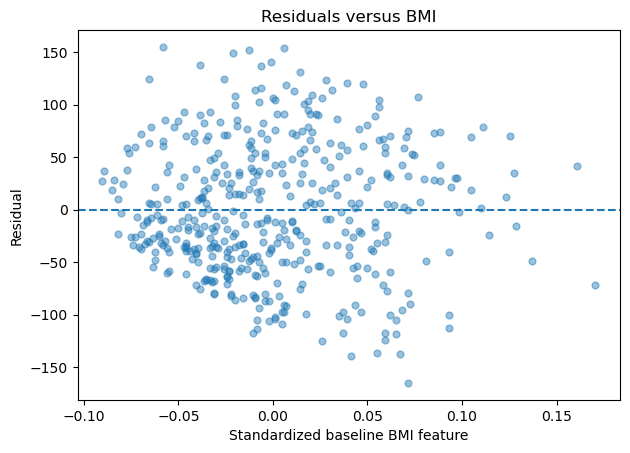

In [5]:
yhat=beta0+beta1*x
resid=y-yhat

plt.scatter(x,resid,alpha=0.45,s=24)
plt.axhline(0,linestyle="--",linewidth=1.5)
plt.xlabel("Standardized baseline BMI feature")
plt.ylabel("Residual")
plt.title("Residuals versus BMI")
plt.show()

The residual contains everything this one-predictor model did not explain:

- biological variability,
- measurement variation,
- omitted predictors,
- nonlinear structure,
- genuinely unpredictable variation.

So "noise" should not automatically be interpreted as measurement error.

## 5. Did using \(X\) actually help?

Compare mean squared error for

$$
\hat y_i=\bar y
$$

versus

$$
\hat y_i=\hat\beta_0+\hat\beta_1x_i.
$$

In [6]:
mse_constant=np.mean((y-ybar)**2)
mse_linear=np.mean((y-yhat)**2)

print(f"MSE, constant predictor = {mse_constant:.2f}")
print(f"MSE, linear predictor   = {mse_linear:.2f}")
print(f"Relative reduction      = {100*(mse_constant-mse_linear)/mse_constant:.1f}%")

MSE, constant predictor = 5929.88
MSE, linear predictor   = 3890.46
Relative reduction      = 34.4%


## 6. Gaussian noise is a stronger model

If we additionally assume

$$
\varepsilon\mid X=x
\sim
\mathcal N(0,\sigma^2),
$$

then

$$
\boxed{
Y\mid X=x
\sim
\mathcal N(\beta_0+\beta_1x,\sigma^2).
}
$$

Now the model specifies not only the conditional mean, but the entire conditional distribution.

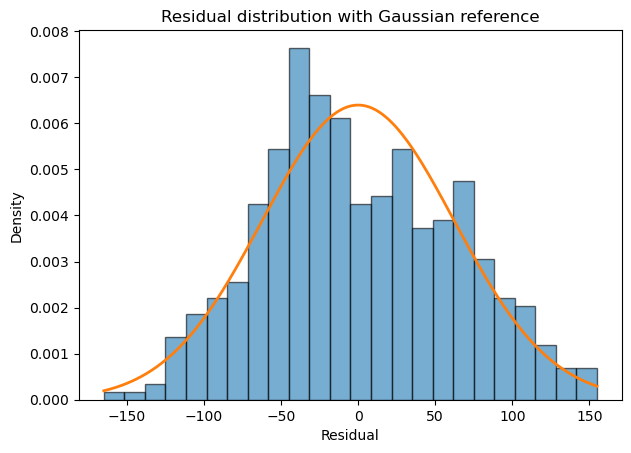

Gaussian-noise MLE sigma = 62.374


In [7]:
sigma=np.sqrt(np.mean(resid**2))

plt.hist(resid,bins=24,density=True,alpha=0.6,edgecolor="black")
grid=np.linspace(resid.min(),resid.max(),300)
plt.plot(grid,stats.norm.pdf(grid,0,sigma),linewidth=2)
plt.xlabel("Residual")
plt.ylabel("Density")
plt.title("Residual distribution with Gaussian reference")
plt.show()

print(f"Gaussian-noise MLE sigma = {sigma:.3f}")

## 7. Bootstrap the slope

The slope is itself an estimator.

Resample patient pairs

$$
(x_i,y_i)
$$

with replacement and refit.

Observed slope = 949.435
Bootstrap median = 950.623
95% bootstrap interval = [835.531, 1060.903]


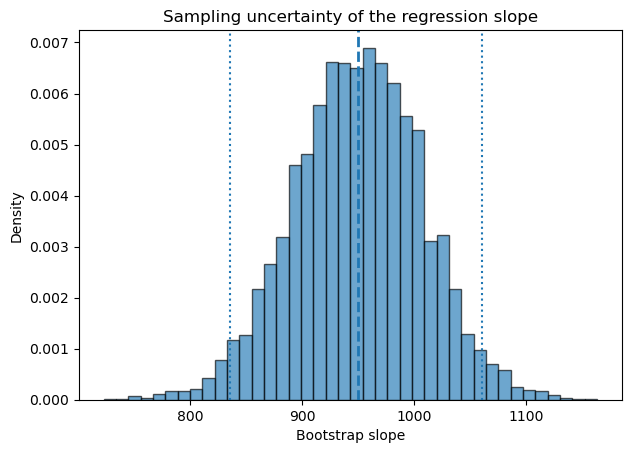

In [8]:
B=5000
n=len(x)
boot_slopes=np.empty(B)

for b in range(B):
    idx=rng.integers(0,n,size=n)
    xb=x[idx]
    yb=y[idx]
    xb_bar=xb.mean()
    yb_bar=yb.mean()

    boot_slopes[b]=(
        np.sum((xb-xb_bar)*(yb-yb_bar))
        /
        np.sum((xb-xb_bar)**2)
    )

q025,q50,q975=np.quantile(boot_slopes,[0.025,0.5,0.975])

print(f"Observed slope = {beta1:.3f}")
print(f"Bootstrap median = {q50:.3f}")
print(f"95% bootstrap interval = [{q025:.3f}, {q975:.3f}]")

plt.hist(boot_slopes,bins=40,density=True,alpha=0.65,edgecolor="black")
plt.axvline(beta1,linestyle="--",linewidth=2)
plt.axvline(q025,linestyle=":",linewidth=1.5)
plt.axvline(q975,linestyle=":",linewidth=1.5)
plt.xlabel("Bootstrap slope")
plt.ylabel("Density")
plt.title("Sampling uncertainty of the regression slope")
plt.show()

# Take-home message

\[
\boxed{
\mathbb E[Y]
\rightarrow
\mathbb E[Y\mid X]
\rightarrow
\beta_0+\beta_1X
}
\]

and

\[
\boxed{
Y=
\underbrace{\mathbb E[Y\mid X]}_{\text{predictable part}}
+
\underbrace{\varepsilon}_{\text{unexplained part}}.
}
\]

Regression reuses the same ideas already developed in the course: expectation, MLE, sampling uncertainty, and bootstrap.